# 이커머스 데이터 분석 리포트

## 개요
- **목적**: 상품·거래 데이터(수치 + 텍스트 + 날짜 + 이미지)를 전처리·분석하고, RFM으로 고객을 세분화해 비즈니스 인사이트를 도출한다.
- **거래 데이터**: Online Retail II (UCI Machine Learning Repository, CC BY 4.0) — https://archive.ics.uci.edu/dataset/502/online+retail+ii
- **이미지 데이터**: Fashion-MNIST (Zalando Research, MIT 라이선스) — Xiao et al. (2017), https://arxiv.org/pdf/1708.07747
- **분석 코드**: `src/pipeline.py`의 `DataAnalyzer` 클래스

## 한계 (먼저 밝혀 둔다)
- 거래 데이터와 이미지 데이터는 출처가 달라서, **상품과 이미지의 연결은 난수(시드 42)로 정한 학습용 시뮬레이션**이다. 이미지 피처(`img_mean`, `img_std`)는 NumPy 벡터 연산 연습용이며, 비즈니스 인사이트에는 사용하지 않는다.

In [1]:
import sys
import warnings

warnings.filterwarnings("ignore")
sys.path.append("..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import font_manager

from src.pipeline import DataAnalyzer

sns.set_theme(style="whitegrid")
for name in ["AppleGothic", "Malgun Gothic", "NanumGothic"]:
    if name in {f.name for f in font_manager.fontManager.ttflist}:
        plt.rcParams["font.family"] = name
        break
plt.rcParams["axes.unicode_minus"] = False

## 1. 데이터 불러오기와 기본 탐색

In [2]:
a = DataAnalyzer()
a.load_data()
print("거래 데이터:", a.df.shape, "| 이미지:", a.images.shape, a.images.dtype)
a.df.info()

거래 데이터: (1067371, 8) | 이미지: (60000, 28, 28) uint8
<class 'pandas.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   invoice      1067371 non-null  str           
 1   stock_code   1067371 non-null  str           
 2   description  1062989 non-null  str           
 3   quantity     1067371 non-null  int64         
 4   order_date   1067371 non-null  datetime64[us]
 5   price        1067371 non-null  float64       
 6   customer_id  824364 non-null   Int64         
 7   country      1067371 non-null  str           
dtypes: Int64(1), datetime64[us](1), float64(1), int64(1), str(4)
memory usage: 66.2 MB


In [3]:
a.df.describe()

,quantity,order_date,price,customer_id
count,1.067371e+06,1067371,1.067371e+06,824364.0
mean,9.938898e+00,2011-01-02 21:13:55.394029,4.649388e+00,15324.638504
min,-8.099500e+04,2009-12-01 07:45:00,-5.359436e+04,12346.0
25%,1.000000e+00,2010-07-09 09:46:00,1.250000e+00,13975.0
50%,3.000000e+00,2010-12-07 15:28:00,2.100000e+00,15255.0
75%,1.000000e+01,2011-07-22 10:23:00,4.150000e+00,16797.0
max,8.099500e+04,2011-12-09 12:50:00,3.897000e+04,18287.0
std,1.727058e+02,NaN,1.235531e+02,1697.46445


In [4]:
a.df.head()

,invoice,stock_code,description,quantity,order_date,price,customer_id,country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom


**해석**
- 거래 데이터는 **1,067,371행 × 8열**이고, 수치(수량·가격·고객번호), 범주(국가·상품코드), 텍스트(상품명), 날짜(주문일)가 섞여 있다. 이미지는 별도로 60,000장(28×28)을 불러왔다.
- `customer_id`는 824,364행에만 값이 있어 **22.8%가 비어 있다**. 누구의 주문인지 알 수 없으므로 RFM 계산에서 제외한다.
- 수량은 중앙값이 3인데 평균이 9.94, 최댓값이 80,995이고, 가격의 최솟값은 −53,594로 음수다. 소수의 극단값과 판매가 아닌 행이 섞여 있다는 뜻이므로, 분석 전에 정제가 필요하다.

## 2. 결측치 현황과 그룹별 대치

In [5]:
missing = a.df.isna().sum()
pd.DataFrame({"빈칸 수": missing, "비율(%)": (missing / len(a.df) * 100).round(1)})

,빈칸 수,비율(%)
invoice,0,0.0
stock_code,0,0.0
description,4382,0.4
quantity,0,0.0
order_date,0,0.0
price,0,0.0
customer_id,243007,22.8
country,0,0.0


In [6]:
no_name = a.df["description"].isna()
print("상품명 빈칸 중 가격 0 이하인 비율:", round((a.df.loc[no_name, "price"] <= 0).mean(), 3))

before = no_name.sum()
a.handle_missing_values()  # 같은 상품 코드의 최빈값으로 상품명 빈칸을 채운다
after = a.df["description"].isna().sum()
print(f"상품명 빈칸: {before:,}개 -> {after:,}개 (채운 비율 {(before - after) / before:.1%})")

상품명 빈칸 중 가격 0 이하인 비율: 1.0
상품명 빈칸: 4,382개 -> 363개 (채운 비율 91.7%)


**해석**
- 상품명 빈칸은 4,382개(0.4%)였고, 같은 상품 코드의 최빈값으로 **4,019개(91.7%)를 채워** 363개가 남았다.
- 빈칸 4,382개는 **전부 가격이 0 이하인 행**이었다. 이 행들은 뒤의 정제 단계에서 판매가 아닌 행으로 제외되므로, 상품명 대치의 실제 효과는 작다.
- 고객 번호 빈칸(22.8%)은 평균으로 채울 수 없는 식별 정보라서 대치하지 않고, RFM 계산에서만 제외한다.

## 3. 피처 엔지니어링 (이미지, 텍스트)
- **이미지**: 상품마다 이미지 한 장을 붙이고, `mean(axis=(1, 2))`로 **반복문 없이** 이미지별 평균·표준편차를 구한다. (연결은 난수 시뮬레이션)
- **텍스트**: 상품명의 단어 수와 글자 수를 센다.

In [7]:
a.add_image_features()
a.add_text_features()
a.df[["stock_code", "description", "img_mean", "img_std", "name_word_count", "name_length"]].head()

,stock_code,description,img_mean,img_std,name_word_count,name_length
0,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,49.910714,42.129413,6.0,35.0
1,79323P,PINK CHERRY LIGHTS,115.840561,98.958460,3.0,18.0
2,79323W,WHITE CHERRY LIGHTS,35.420918,71.006333,3.0,20.0
3,22041,"RECORD FRAME 7"" SINGLE SIZE",89.276786,106.531631,5.0,28.0
4,21232,STRAWBERRY CERAMIC TRINKET BOX,72.963010,68.898198,4.0,30.0


In [8]:
a.df[["img_mean", "img_std", "name_word_count", "name_length"]].describe().round(2)

,img_mean,img_std,name_word_count,name_length
count,1067371.00,1067371.00,1067008.00,1067008.00
mean,73.91,82.15,4.39,26.68
std,32.91,20.52,1.09,5.46
min,8.67,16.53,1.00,1.00
25%,48.46,66.67,4.00,23.00
50%,69.81,85.62,4.00,27.00
75%,99.33,98.71,5.00,31.00
max,179.95,119.44,8.00,35.00


> **해석** _(실행 결과를 확인한 뒤 작성: 수치 근거 1개 이상 + 시사점 1문장 이상)_

## 4. 데이터 정제
중복 행, 취소 주문(`C`로 시작), 수량·가격이 0 이하인 행을 제거하고 주문 금액(`amount = quantity × price`)을 만든다.

In [9]:
n0 = len(a.df)
dup = a.df.duplicated().sum()
a.clean_data()
print(f"정제 전 {n0:,}행 | 중복 {dup:,}행 | 정제 후 {len(a.df):,}행 (제거 {n0 - len(a.df):,}행, {(n0 - len(a.df)) / n0:.1%})")
a.df[["quantity", "price", "amount"]].min()

정제 전 1,067,371행 | 중복 34,335행 | 정제 후 1,007,913행 (제거 59,458행, 5.6%)


quantity    1.000
price       0.001
amount      0.001
dtype: float64

**해석**
- 정제 전 1,067,371행에서 **1,007,913행이 남았다**(59,458행, 5.6% 제거). 정제 후 수량·가격·금액의 최솟값이 모두 0보다 커서 판매가 아닌 행이 없어졌음을 확인했다.
- 시사점: 이후의 통계와 RFM은 '실제 판매'만을 기준으로 계산한다. 다만 취소된 주문의 **원래 주문은 남아 있어** 매출이 일부 과대 계상될 수 있다(아래 5번 참고).

## 5. 이상치 탐지와 범위 제한 (IQR)
IQR = Q3 − Q1. 위 울타리 = Q3 + 1.5 × IQR, 아래 울타리 = Q1 − 1.5 × IQR. 울타리 밖의 값을 이상치로 본다.
이상치는 삭제하지 않고 울타리 값으로 **범위 제한(클리핑, clipping)** 해서 새 열(`*_clipped`)에 저장한다.

In [10]:
rows = []
for col in ["quantity", "price", "amount"]:
    lower, upper = a._iqr_bounds(col, 1.5)
    n = len(a.detect_outliers(col))
    rows.append({"변수": col, "이상치 수": n, "비율(%)": round(n / len(a.df) * 100, 1),
                 "아래 울타리": round(lower, 2), "위 울타리": round(upper, 2)})
pd.DataFrame(rows)

,변수,이상치 수,비율(%),아래 울타리,위 울타리
0,quantity,53061,5.3,-15.50,28.50
1,price,78999,7.8,-3.07,8.45
2,amount,84954,8.4,-16.23,38.06


In [11]:
for col in ["quantity", "price", "amount"]:
    a.clip_outliers(col)
a.df[["quantity", "quantity_clipped"]].describe().round(2)

,quantity,quantity_clipped
count,1007913.00,1007913.00
mean,11.12,7.07
std,128.47,7.93
min,1.00,1.00
25%,1.00,1.00
50%,4.00,4.00
75%,12.00,12.00
max,80995.00,28.50


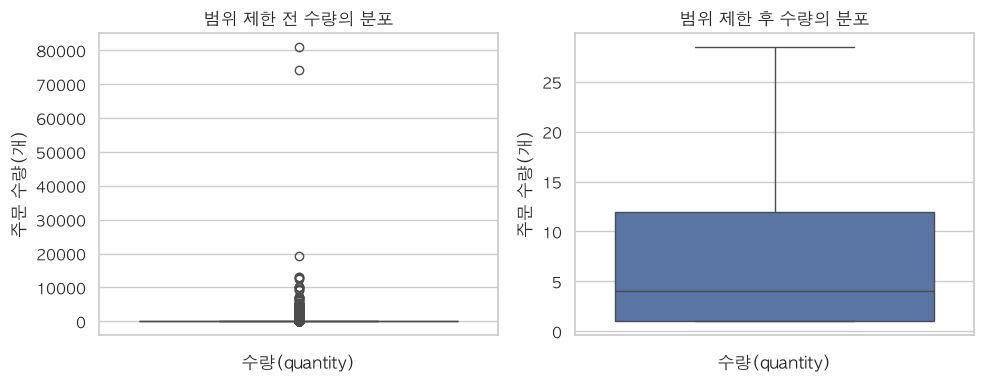

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.boxplot(y=a.df["quantity"], ax=axes[0])
axes[0].set_title("범위 제한 전 수량의 분포")
axes[1].set_title("범위 제한 후 수량의 분포")
sns.boxplot(y=a.df["quantity_clipped"], ax=axes[1])
for ax in axes:
    ax.set_xlabel("수량(quantity)")
    ax.set_ylabel("주문 수량(개)")
plt.tight_layout()
plt.show()

In [13]:
raw = DataAnalyzer().load_data()
raw[raw["quantity"].abs() == 80995][["invoice", "customer_id", "quantity", "price", "order_date"]]

,invoice,customer_id,quantity,price,order_date
1065882,581483,16446,80995,2.08,2011-12-09 09:15:00
1065883,C581484,16446,-80995,2.08,2011-12-09 09:27:00


**해석**
- IQR(1.5배) 기준 이상치는 수량 **53,061행(5.3%)**, 가격 78,999행(7.8%), 금액 84,954행(8.4%)이었다. 수량의 위 울타리는 28.5이다.
- 범위 제한 후 수량의 **평균은 11.12에서 7.07로 줄었지만 중앙값(4), Q1(1), Q3(12)은 그대로**였다. 분포의 가운데는 두고 꼬리만 눌렀다는 뜻이다.
- 시사점: 소수의 대량 주문이 평균을 크게 끌어올리고 있어, 이 데이터에서는 평균보다 중앙값이 대표값으로 적합하다. 이상치가 5%를 넘으므로 오류라기보다 대량 주문일 가능성이 있어 삭제하지 않았다.
- **한계**: 가장 큰 값인 80,995개 주문(주문번호 581483)은 12분 뒤 같은 고객이 전량 취소(C581484)했다. 취소 행만 제거하므로 이 원래 주문은 남아 있다. 이 때문에 해당 고객의 구매 금액이 약 168,470으로 부풀려졌다.

## 6. 통계 분석

In [14]:
stats = a.df[["quantity", "price", "amount"]].describe().T[["mean", "50%", "std", "25%", "75%"]]
stats.columns = ["평균", "중앙값", "표준편차", "Q1", "Q3"]
stats.round(2)

,평균,중앙값,표준편차,Q1,Q3
quantity,11.12,4.00,128.47,1.00,12.00
price,4.07,2.10,50.43,1.25,4.13
amount,20.32,10.08,205.72,4.13,17.70


**해석**
- 세 변수 모두 평균이 중앙값보다 크다. 예를 들어 **주문 금액의 평균은 20.32, 중앙값은 10.08로 약 2배** 차이가 나고, 표준편차(205.72)는 평균보다 훨씬 크다. 소수의 큰 주문이 평균을 끌어올리는 오른쪽 꼬리가 긴 분포다.
- 시사점: 평균만 보면 전형적인 주문을 과대평가한다. 전형적인 주문 금액은 Q1~Q3인 **약 4~18 사이**이므로, 중앙값과 사분위수를 함께 봐야 한다.

price_clipped - quantity_clipped: -0.379
name_word_count - price_clipped: -0.032
img_mean - amount_clipped: -0.012


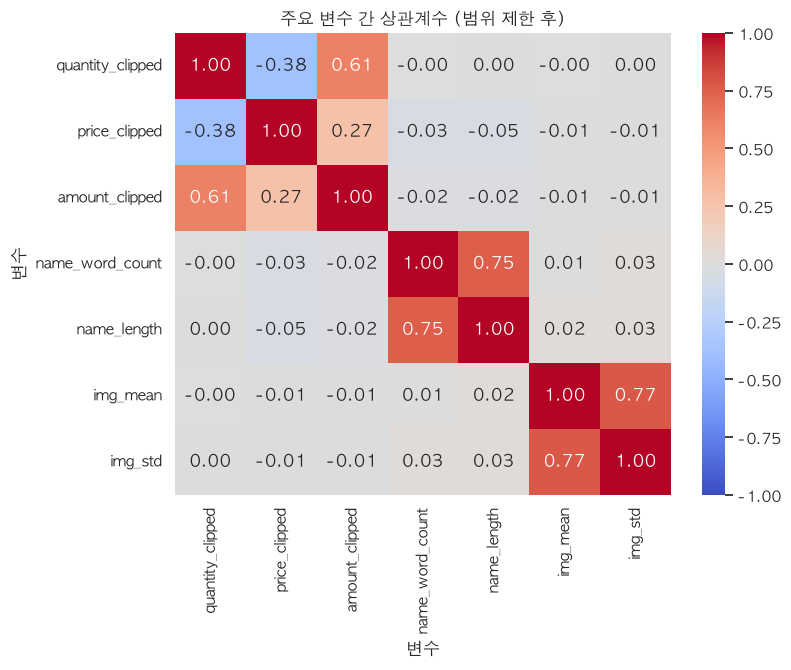

In [15]:
pairs = [("price_clipped", "quantity_clipped"), ("name_word_count", "price_clipped"), ("img_mean", "amount_clipped")]
for x, y in pairs:
    print(f"{x} - {y}: {a.df[x].corr(a.df[y]):.3f}")

cols = ["quantity_clipped", "price_clipped", "amount_clipped", "name_word_count", "name_length", "img_mean", "img_std"]
plt.figure(figsize=(8, 6))
sns.heatmap(a.df[cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("주요 변수 간 상관계수 (범위 제한 후)")
plt.xlabel("변수")
plt.ylabel("변수")
plt.show()

> **해석** _(실행 결과를 확인한 뒤 작성: 수치 근거 1개 이상 + 시사점 1문장 이상)_
>
> 참고: `img_mean`과 금액은 이미지를 난수로 붙였으므로 상관이 0에 가까워야 정상이다.

## 7. 분포와 추세 시각화

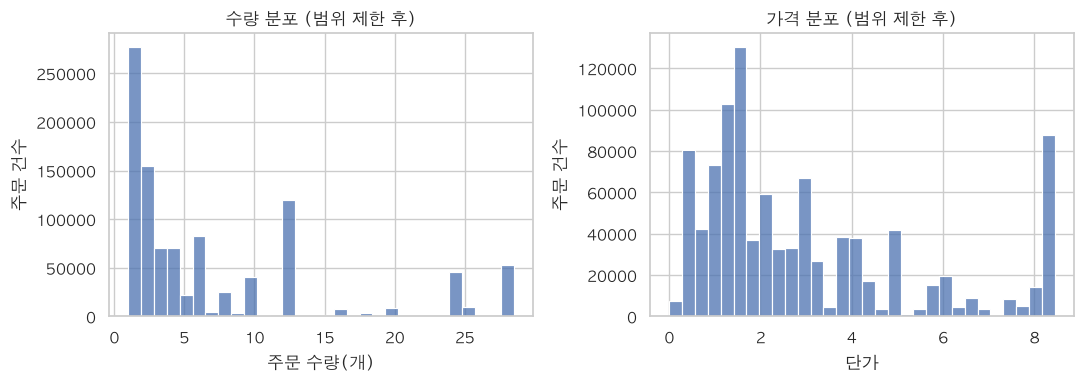

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(a.df["quantity_clipped"], bins=30, ax=axes[0])
axes[0].set_title("수량 분포 (범위 제한 후)")
axes[0].set_xlabel("주문 수량(개)")
axes[0].set_ylabel("주문 건수")
sns.histplot(a.df["price_clipped"], bins=30, ax=axes[1])
axes[1].set_title("가격 분포 (범위 제한 후)")
axes[1].set_xlabel("단가")
axes[1].set_ylabel("주문 건수")
plt.tight_layout()
plt.show()

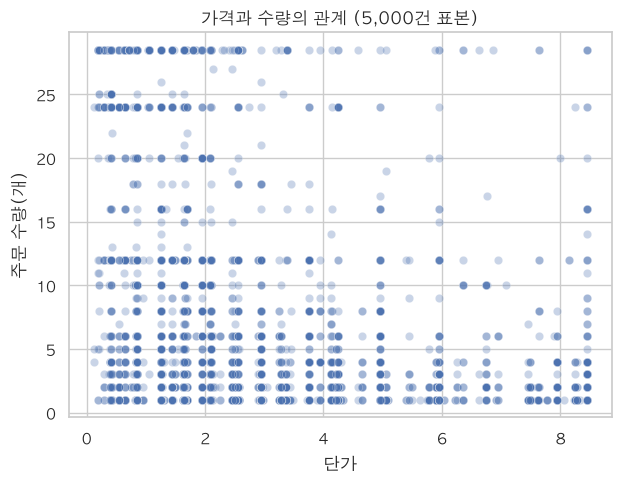

In [17]:
sample = a.df.sample(5000, random_state=42)
plt.figure(figsize=(7, 5))
sns.scatterplot(data=sample, x="price_clipped", y="quantity_clipped", alpha=0.3)
plt.title("가격과 수량의 관계 (5,000건 표본)")
plt.xlabel("단가")
plt.ylabel("주문 수량(개)")
plt.show()

마지막 달(2011-12)은 9일치 데이터라 제외했다.


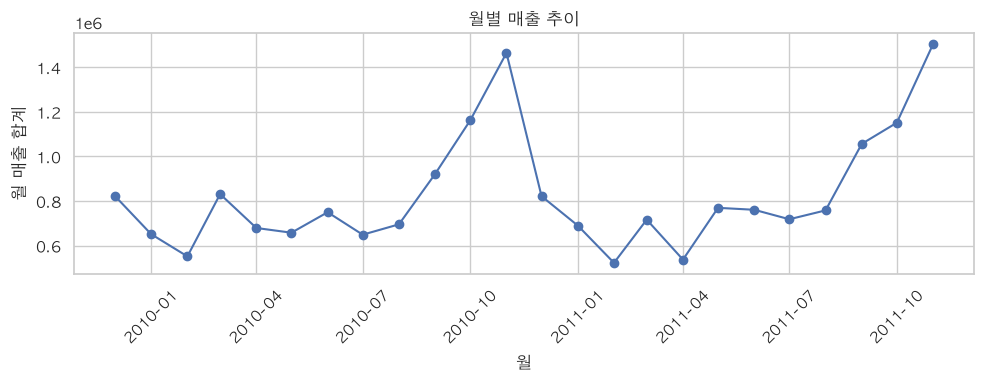

order_date
2011-11-01    1503867.0
2010-11-01    1464293.0
2010-10-01    1161902.0
Name: amount, dtype: float64

In [18]:
monthly = a.df.groupby(a.df["order_date"].dt.to_period("M"))["amount"].sum().iloc[:-1]
monthly.index = monthly.index.to_timestamp()
print("마지막 달(2011-12)은 9일치 데이터라 제외했다.")

plt.figure(figsize=(10, 4))
plt.plot(monthly.index, monthly.values, marker="o")
plt.title("월별 매출 추이")
plt.xlabel("월")
plt.ylabel("월 매출 합계")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
monthly.round(0).sort_values(ascending=False).head(3)

> **해석** _(실행 결과를 확인한 뒤 작성: 수치 근거 1개 이상 + 시사점 1문장 이상)_

## 8. RFM 고객 세분화
- **R(Recency)**: 데이터의 마지막 거래일(2011-12-09)에서 고객의 마지막 구매일을 뺀 일수
- **F(Frequency)**: 서로 다른 주문번호의 개수
- **M(Monetary)**: 주문 금액(`amount`)의 합계. 범위 제한 전의 원본 금액을 쓴다.
- 각각 1~5점(5점이 가장 좋음)을 매기고, 아래 규칙으로 세그먼트를 나눈다. 고객 번호가 없는 행은 제외한다.

| 세그먼트 | 조건 | 뜻 |
|---|---|---|
| VIP | R≥4, F≥4, M≥4 | 최근에, 자주, 많이 구매 |
| Loyal | F≥4, R≥3 | 꾸준히 구매하는 단골 |
| New | R≥4, F≤2 | 최근에 샀지만 횟수가 적음 |
| Churned | R≤2 | 오래전에 마지막으로 구매(이탈) |
| Regular | 나머지 | 중간층 |

조건은 위에서부터 차례로 확인하고, 처음 맞는 세그먼트를 붙인다.

In [19]:
rfm = a.calculate_rfm()
rfm.head()

,frequency,monetary,recency,R,F,M,segment
customer_id,,,,,,,
12346,12,77556.46,325,2,5,5,Churned
12347,8,4921.53,1,5,4,5,VIP
12348,5,2019.40,74,3,4,4,Loyal
12349,4,4428.69,18,5,3,5,Regular
12350,1,334.40,309,2,1,2,Churned


In [20]:
order = ["VIP", "Loyal", "New", "Regular", "Churned"]
g = rfm.groupby("segment")
summary = pd.DataFrame({
    "고객수": g.size(),
    "고객비율(%)": (g.size() / len(rfm) * 100).round(1),
    "평균 recency": g["recency"].mean().round(1),
    "평균 frequency": g["frequency"].mean().round(1),
    "평균 monetary": g["monetary"].mean().round(0),
    "중앙값 monetary": g["monetary"].median().round(0),
    "금액 비중(%)": (g["monetary"].sum() / rfm["monetary"].sum() * 100).round(1),
}).loc[order]
summary

,고객수,고객비율(%),평균 recency,평균 frequency,평균 monetary,중앙값 monetary,금액 비중(%)
segment,,,,,,,
VIP,1274,21.7,18.8,17.3,9276.0,4002.0,68.0
Loyal,604,10.3,85.3,8.3,2916.0,1895.0,10.1
New,506,8.6,26.5,1.5,836.0,383.0,2.4
Regular,1147,19.5,76.1,2.7,984.0,715.0,6.5
Churned,2347,39.9,426.6,2.5,956.0,406.0,12.9


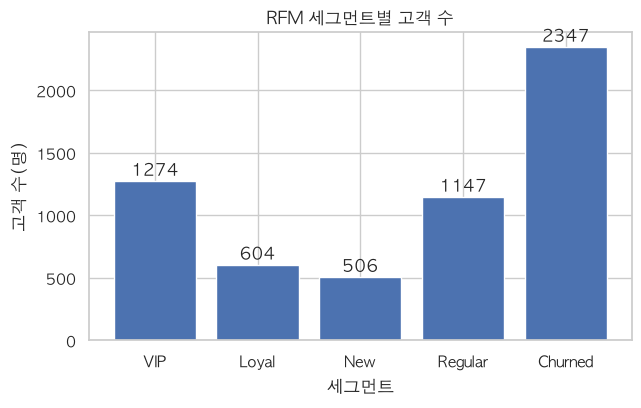

In [21]:
plt.figure(figsize=(7, 4))
bars = plt.bar(summary.index, summary["고객수"])
plt.bar_label(bars)
plt.title("RFM 세그먼트별 고객 수")
plt.xlabel("세그먼트")
plt.ylabel("고객 수(명)")
plt.show()

**해석**
- 고객 **5,878명**을 5개 세그먼트로 나눴다. VIP는 1,274명(21.7%)으로 평균 구매 횟수 17.3회, 평균 구매 금액 9,276, 마지막 구매 후 평균 18.8일이다. 위 표의 금액 비중 열에서 VIP가 전체 구매 금액의 **약 3분의 2(약 68%)** 를 차지함을 확인할 수 있다.
- Churned는 2,347명(39.9%)으로 가장 크고, 마지막 구매 후 평균 **427일**이 지났다. New는 506명(8.6%)이고 평균 구매 횟수가 1.5회다.
- 시사점: 매출이 소수의 VIP에 집중되어 있고 고객의 40%가 이탈 상태이므로, **VIP 유지와 이탈 고객 복귀**가 우선 과제다.
- 주의: 구매 금액은 소수의 초대형 고객(최댓값 580,987)에 평균이 끌려 올라갈 수 있어 중앙값을 함께 표시했다. 또한 크리스마스 용품이 많은 업체라 연말에만 구매하는 고객이 Churned에 섞여 있을 수 있다.

## 9. 한계
- 이미지와 상품의 연결은 난수 시뮬레이션이다. 이미지 피처는 인사이트에 쓰지 않았다.
- 취소 주문(`C`)은 제외했지만, 취소된 원래 주문은 남아 있어 매출과 구매 금액이 일부 과대 계상될 수 있다.
- 완전 중복 행을 모두 제거했으므로, 같은 주문 안에서 같은 상품을 두 번 입력한 정상 행도 함께 제거되었을 수 있다.
- 마지막 달(2011-12)은 9일치라 월별 매출 추이에서 제외했다.
- 세그먼트 기준(점수 4 이상 등)은 분석자가 정한 규칙이며, 다른 기준을 쓰면 고객 수가 달라질 수 있다.